> **Public-release note:** The notebook code uses repository-relative input/output locations. Saved execution outputs below are from a previous run and are retained for inspection; historic personal filesystem prefixes have been redacted. The code was not re-executed for this release.


In [1]:
# نصب کتابخانه‌ها در صورت نیاز

import sys
import subprocess
import importlib.util

required_packages = {
    "pandas": "pandas",
    "numpy": "numpy",
    "matplotlib": "matplotlib",
    "pyarrow": "pyarrow",
    "scipy": "scipy",
    "sklearn": "scikit-learn",
    "joblib": "joblib",
}

for module_name, package_name in required_packages.items():
    if importlib.util.find_spec(module_name) is None:
        print(f"Installing {package_name} ...")
        subprocess.check_call(
            [sys.executable, "-m", "pip", "install", "-q", package_name]
        )

print("All required packages are available.")

All required packages are available.


In [2]:
from pathlib import Path
import os
from itertools import combinations
import gc
import json
import math
import time
import warnings

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from scipy.optimize import minimize_scalar
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score,
    log_loss,
)
from sklearn.preprocessing import LabelEncoder, StandardScaler

warnings.filterwarnings("ignore")

pd.set_option("display.max_columns", 250)
pd.set_option("display.max_rows", 300)
pd.set_option("display.max_colwidth", 180)

EPSILON = 1e-12
RANDOM_STATE_MODEL = 142
np.random.seed(42)

In [3]:
RUN_MODE = "full"  # "pilot" or "full"

PILOT_TARGET_OUTER_FOLDS = [1]
FULL_TARGET_OUTER_FOLDS = [1, 2, 3, 4, 5]

ACTIVE_TARGET_OUTER_FOLDS = (
    PILOT_TARGET_OUTER_FOLDS
    if RUN_MODE == "pilot"
    else FULL_TARGET_OUTER_FOLDS
)

# Portable paths shared with the baseline notebooks.
# Start Jupyter in the repository root or notebooks/ folder,
# or set FORCE_REPO_ROOT to your local repository folder.
REPO_ROOT = Path(os.environ.get("FORCE_REPO_ROOT", Path.cwd())).expanduser().resolve()
if REPO_ROOT.name == "notebooks":
    REPO_ROOT = REPO_ROOT.parent
if not (REPO_ROOT / "notebooks").is_dir():
    raise FileNotFoundError(
        "Repository root not found. Launch Jupyter from the repository root "
        "or notebooks/, or set FORCE_REPO_ROOT."
    )
DATA_DIR = Path(
    os.environ.get("FORCE_DATA_DIR", str(REPO_ROOT / "data" / "raw"))
).expanduser().resolve()
PREPARED_DIR = Path(
    os.environ.get("FORCE_PREPARED_DIR", str(REPO_ROOT / "data" / "prepared"))
).expanduser().resolve()
RESULTS_ROOT = Path(
    os.environ.get("FORCE_RESULTS_DIR", str(REPO_ROOT / "outputs"))
).expanduser().resolve()

TRAIN_PATH = DATA_DIR / "train.csv"
PROJECT_ROOT = RESULTS_ROOT
STAGE_01_DIR = PREPARED_DIR
FOLD_ASSIGNMENT_PATH = STAGE_01_DIR / "10_grouped_5fold_well_assignment.csv"
STAGE_02B_DIR = PROJECT_ROOT / "02B_legacy_RF_grouped_well_CV" / "full"
OUTER_OOF_DIR = STAGE_02B_DIR / "oof_predictions"
STAGE_02B_CONFIG_PATH = STAGE_02B_DIR / "12_run_configuration.json"

# خروجی اصلی این مرحله
OUTPUT_ROOT = (
    PROJECT_ROOT
    / "03_nested_grouped_temperature_calibration"
)

RUN_OUTPUT_DIR = (
    OUTPUT_ROOT
    / RUN_MODE
)

# Cache مشترک بین Pilot و Full
PAIR_CACHE_DIR = (
    OUTPUT_ROOT
    / "pair_oof_cache"
)

PAIR_SUMMARY_DIR = (
    OUTPUT_ROOT
    / "pair_summaries"
)

PAIR_IMPORTANCE_DIR = (
    OUTPUT_ROOT
    / "pair_feature_importance"
)

PAIR_RESAMPLING_DIR = (
    OUTPUT_ROOT
    / "pair_resampling_audits"
)

PAIR_MODEL_DIR = (
    OUTPUT_ROOT
    / "pair_models"
)

CALIBRATED_OUTER_OOF_DIR = (
    RUN_OUTPUT_DIR
    / "calibrated_outer_oof"
)

INNER_OOF_DIR = (
    RUN_OUTPUT_DIR
    / "nested_inner_oof"
)

PLOT_DIR = (
    RUN_OUTPUT_DIR
    / "plots"
)

for directory in [
    OUTPUT_ROOT,
    RUN_OUTPUT_DIR,
    PAIR_CACHE_DIR,
    PAIR_SUMMARY_DIR,
    PAIR_IMPORTANCE_DIR,
    PAIR_RESAMPLING_DIR,
    PAIR_MODEL_DIR,
    CALIBRATED_OUTER_OOF_DIR,
    INNER_OOF_DIR,
    PLOT_DIR,
]:
    directory.mkdir(
        parents=True,
        exist_ok=True,
    )

# همان Random Forest مقاله قبلی
RF_N_ESTIMATORS = 800
RF_MAX_DEPTH = 200
RF_MIN_SAMPLES_SPLIT = 5
RF_MIN_SAMPLES_LEAF = 2
RF_N_JOBS = -1

SAVE_PAIR_MODELS = False
SKIP_COMPLETED_PAIRS = True

# Temperature scaling
MIN_TEMPERATURE = 0.05
MAX_TEMPERATURE = 10.0
N_BINS = 15

if not TRAIN_PATH.exists():
    raise FileNotFoundError(TRAIN_PATH)

if not FOLD_ASSIGNMENT_PATH.exists():
    raise FileNotFoundError(FOLD_ASSIGNMENT_PATH)

if not OUTER_OOF_DIR.exists():
    raise FileNotFoundError(OUTER_OOF_DIR)

print("RUN_MODE:", RUN_MODE)
print("Target outer folds:", ACTIVE_TARGET_OUTER_FOLDS)
print("Pair cache:", PAIR_CACHE_DIR)
print("Output:", RUN_OUTPUT_DIR)

RUN_MODE: full
Target outer folds: [1, 2, 3, 4, 5]
Pair cache: <historical-results-root>/03_nested_grouped_temperature_calibration/pair_oof_cache
Output: <historical-results-root>/03_nested_grouped_temperature_calibration/full


In [4]:
def detect_csv_format(
    file_path,
    num_lines=5,
):
    encodings = [
        "utf-8",
        "latin1",
        "iso-8859-1",
        "cp1252",
    ]

    for encoding in encodings:
        try:
            with open(
                file_path,
                "r",
                encoding=encoding,
            ) as file:
                first_lines = [
                    file.readline()
                    for _ in range(num_lines)
                ]

            if any("," in line for line in first_lines):
                delimiter = ","
            elif any(";" in line for line in first_lines):
                delimiter = ";"
            elif any("\t" in line for line in first_lines):
                delimiter = "\t"
            else:
                delimiter = ","

            return {
                "sep": delimiter,
                "encoding": encoding,
            }

        except UnicodeDecodeError:
            continue

    return {
        "sep": ",",
        "encoding": "utf-8",
    }


def load_csv_full(
    file_path,
):
    csv_format = detect_csv_format(
        file_path
    )

    print(
        f"Loading {file_path.name} "
        f"with {csv_format}"
    )

    return pd.read_csv(
        file_path,
        sep=csv_format["sep"],
        encoding=csv_format["encoding"],
        low_memory=False,
    )


train_raw = load_csv_full(
    TRAIN_PATH
)

fold_assignment_raw = pd.read_csv(
    FOLD_ASSIGNMENT_PATH
)

well_candidates = [
    column
    for column in fold_assignment_raw.columns
    if column.upper() == "WELL"
]

fold_candidates = [
    column
    for column in fold_assignment_raw.columns
    if (
        "FOLD" in column.upper()
        and "SCORE" not in column.upper()
    )
]

if not well_candidates or not fold_candidates:
    raise ValueError(
        "Could not infer WELL/FOLD columns "
        "from fold assignment file."
    )

assignment_well_column = (
    well_candidates[0]
)

assignment_fold_column = (
    fold_candidates[0]
)

fold_assignment = (
    fold_assignment_raw[
        [
            assignment_well_column,
            assignment_fold_column,
        ]
    ]
    .rename(
        columns={
            assignment_well_column: "WELL",
            assignment_fold_column: "GROUP_FOLD",
        }
    )
    .drop_duplicates(
        subset=["WELL"]
    )
    .copy()
)

fold_assignment[
    "GROUP_FOLD"
] = pd.to_numeric(
    fold_assignment[
        "GROUP_FOLD"
    ],
    errors="raise",
).astype(int)

well_to_fold = dict(
    zip(
        fold_assignment["WELL"],
        fold_assignment["GROUP_FOLD"],
    )
)

train_raw[
    "GROUP_FOLD"
] = train_raw[
    "WELL"
].map(
    well_to_fold
)

missing_fold_wells = sorted(
    train_raw.loc[
        train_raw["GROUP_FOLD"].isna(),
        "WELL",
    ]
    .dropna()
    .unique()
    .tolist()
)

if missing_fold_wells:
    raise RuntimeError(
        "Train wells without grouped fold assignment: "
        f"{missing_fold_wells[:20]}"
    )

train_raw[
    "GROUP_FOLD"
] = train_raw[
    "GROUP_FOLD"
].astype(int)

observed_folds = sorted(
    train_raw[
        "GROUP_FOLD"
    ].unique()
)

if observed_folds != [1, 2, 3, 4, 5]:
    raise RuntimeError(
        f"Unexpected folds: {observed_folds}"
    )

fold_assignment_summary = (
    train_raw.groupby(
        "GROUP_FOLD"
    )
    .agg(
        row_count=(
            "WELL",
            "size",
        ),
        well_count=(
            "WELL",
            "nunique",
        ),
    )
    .reset_index()
)

display(fold_assignment_summary)

Loading train.csv with {'sep': ',', 'encoding': 'utf-8'}


,GROUP_FOLD,row_count,well_count
0,1,232674,20
1,2,236205,20
2,3,230578,21
3,4,237132,17
4,5,233922,20


In [5]:
if STAGE_02B_CONFIG_PATH.exists():
    with open(
        STAGE_02B_CONFIG_PATH,
        "r",
        encoding="utf-8",
    ) as file:
        stage_02b_config = json.load(file)

    if stage_02b_config.get(
        "official_test_used",
        True,
    ):
        raise RuntimeError(
            "Stage 02B used the official test."
        )

    if not stage_02b_config.get(
        "legacy_model_unchanged",
        False,
    ):
        raise RuntimeError(
            "Stage 02B did not preserve the legacy model."
        )

    if stage_02b_config.get(
        "outer_split",
        {},
    ).get("group") != "WELL":
        raise RuntimeError(
            "Stage 02B was not grouped by WELL."
        )

print("Stage 02B audit passed.")

Stage 02B audit passed.


In [6]:
TARGET_COLUMN = (
    "FORCE_2020_LITHOFACIES_LITHOLOGY"
)

CONFIDENCE_COLUMN = (
    "FORCE_2020_LITHOFACIES_CONFIDENCE"
)

LITHOLOGY_CODES = sorted([
    30000,
    65030,
    65000,
    80000,
    74000,
    70000,
    70032,
    88000,
    86000,
    99000,
    90000,
    93000,
])

LITHOLOGY_NAMES = {
    30000: "Sandstone",
    65000: "Shale",
    65030: "Sandstone/Shale",
    70000: "Limestone",
    70032: "Chalk",
    74000: "Dolomite",
    80000: "Marl",
    86000: "Anhydrite",
    88000: "Halite",
    90000: "Coal",
    93000: "Basement",
    99000: "Tuff",
}

label_encoder = LabelEncoder()
label_encoder.fit(
    LITHOLOGY_CODES
)

CLASS_CODES = [
    int(value)
    for value in label_encoder.classes_
]

CLASS_INDICES = list(
    range(len(CLASS_CODES))
)

PROBABILITY_COLUMNS = [
    f"prob_{class_code}"
    for class_code in CLASS_CODES
]

CALIBRATED_PROBABILITY_COLUMNS = [
    f"nested_calibrated_prob_{class_code}"
    for class_code in CLASS_CODES
]

TOP_LEGACY_FEATURES = [
    "GR_NPHI_interaction",
    "GR_DTC_interaction",
    "Y_LOC",
    "GR_RHOB_RATIO",
    "NPHI_DTC_interaction",
    "X_LOC",
    "RHOB_DTC_interaction",
    "CALI",
    "Z_LOC",
    "GR_RHOB_interaction",
    "DEPTH_NORMALIZED",
    "DEPTH_MD",
    "RDEP",
    "RHOB_log",
    "RMED",
    "RHOB",
    "X_LOC",
]

EXTRA_WEAK_CLASS_FEATURES = [
    "GR_flatness",
    "DTC_grad",
    "DTC_RHOB_DIFF",
    "DTC_RHOB_RATIO2",
    "RDEP_GR_RATIO",
    "RHOB_NPHI_DIFF2",
    "Acoustic_Impedance",
    "Sand_indicator",
    "Shale_indicator",
]

LEGACY_FEATURE_COLUMNS = (
    TOP_LEGACY_FEATURES
    + EXTRA_WEAK_CLASS_FEATURES
)

assert len(LEGACY_FEATURE_COLUMNS) == 26
assert len(set(LEGACY_FEATURE_COLUMNS)) == 25
assert LEGACY_FEATURE_COLUMNS.count("X_LOC") == 2

print("Legacy feature count:", len(LEGACY_FEATURE_COLUMNS))

Legacy feature count: 26


In [7]:
def fit_and_apply_train_imputers(
    dataframe,
):
    df = dataframe.copy()

    if CONFIDENCE_COLUMN in df.columns:
        df = df.drop(
            columns=[CONFIDENCE_COLUMN]
        )

    numeric_columns = (
        df.select_dtypes(
            include=[np.number]
        )
        .columns
        .tolist()
    )

    for excluded in [
        TARGET_COLUMN,
        "LITHOLOGY_ENCODED",
        "GROUP_FOLD",
    ]:
        if excluded in numeric_columns:
            numeric_columns.remove(excluded)

    imputers = {}

    for column in numeric_columns:
        if df[column].isna().any():
            imputer = SimpleImputer(
                strategy="median"
            )

            df[column] = (
                imputer
                .fit_transform(
                    df[[column]]
                )
                .ravel()
            )

            imputers[column] = imputer

    df[numeric_columns] = (
        df[numeric_columns]
        .fillna(0)
        .replace(
            [np.inf, -np.inf],
            0,
        )
    )

    return df, imputers


def apply_train_imputers_to_validation(
    dataframe,
    imputers,
):
    df = dataframe.copy()

    if CONFIDENCE_COLUMN in df.columns:
        df = df.drop(
            columns=[CONFIDENCE_COLUMN]
        )

    numeric_columns = (
        df.select_dtypes(
            include=[np.number]
        )
        .columns
        .tolist()
    )

    for excluded in [
        TARGET_COLUMN,
        "LITHOLOGY_ENCODED",
        "GROUP_FOLD",
    ]:
        if excluded in numeric_columns:
            numeric_columns.remove(excluded)

    for column in numeric_columns:
        if (
            column in imputers
            and df[column].isna().any()
        ):
            df[column] = (
                imputers[column]
                .transform(
                    df[[column]]
                )
                .ravel()
            )

    df[numeric_columns] = (
        df[numeric_columns]
        .fillna(0)
        .replace(
            [np.inf, -np.inf],
            0,
        )
    )

    return df


def add_legacy_preprocess_features(
    dataframe,
):
    df = dataframe.copy()
    epsilon = 1e-10

    if {"NPHI", "RHOB"}.issubset(df.columns):
        df["NPHI_RHOB_RATIO"] = (
            df["NPHI"]
            / (
                df["RHOB"].abs()
                + epsilon
            )
        )

    if {"GR", "RHOB"}.issubset(df.columns):
        df["GR_RHOB_RATIO"] = (
            df["GR"]
            / (
                df["RHOB"].abs()
                + epsilon
            )
        )

    if {"DTC", "RHOB"}.issubset(df.columns):
        df["DTC_RHOB_RATIO"] = (
            df["DTC"]
            / (
                df["RHOB"].abs()
                + epsilon
            )
        )

    if "DEPTH_MD" in df.columns:
        depth_min = df["DEPTH_MD"].min()
        depth_max = df["DEPTH_MD"].max()
        depth_range = depth_max - depth_min

        if depth_range > 0:
            df["DEPTH_NORMALIZED"] = (
                (
                    df["DEPTH_MD"]
                    - depth_min
                )
                / depth_range
            )
        else:
            df["DEPTH_NORMALIZED"] = 0.0

    numeric_columns = (
        df.select_dtypes(
            include=[np.number]
        )
        .columns
    )

    df[numeric_columns] = (
        df[numeric_columns]
        .fillna(0)
        .replace(
            [np.inf, -np.inf],
            0,
        )
    )

    return df


def encode_target(
    dataframe,
):
    df = dataframe.copy()

    numeric_target = (
        pd.to_numeric(
            df[TARGET_COLUMN],
            errors="raise",
        )
        .astype(int)
    )

    unknown_codes = sorted(
        set(numeric_target)
        - set(CLASS_CODES)
    )

    if unknown_codes:
        raise ValueError(
            f"Unknown lithology codes: {unknown_codes}"
        )

    df[TARGET_COLUMN] = numeric_target

    df["LITHOLOGY_ENCODED"] = (
        label_encoder.transform(
            numeric_target
        )
    )

    return df


def apply_legacy_exact_resampling(
    dataframe,
):
    df = dataframe.copy()

    before_counts = (
        df[TARGET_COLUMN]
        .value_counts()
        .sort_index()
    )

    def drop_fraction(
        source_df,
        class_code,
        fraction,
        random_state,
    ):
        class_mask = (
            source_df[TARGET_COLUMN]
            == class_code
        )

        class_count = int(
            class_mask.sum()
        )

        if class_count == 0:
            return source_df

        n_to_drop = int(
            class_count
            * fraction
        )

        indices_to_drop = (
            source_df.loc[
                class_mask
            ]
            .sample(
                n=n_to_drop,
                random_state=random_state,
            )
            .index
        )

        return source_df.drop(
            indices_to_drop
        )

    df = drop_fraction(
        df,
        class_code=65000,
        fraction=0.30,
        random_state=86,
    )

    df = drop_fraction(
        df,
        class_code=30000,
        fraction=0.20,
        random_state=86,
    )

    df = drop_fraction(
        df,
        class_code=70000,
        fraction=0.20,
        random_state=142,
    )

    df = drop_fraction(
        df,
        class_code=65030,
        fraction=0.20,
        random_state=142,
    )

    # رفتار واقعی Legacy حفظ می‌شود.
    basement_mask = (
        df[TARGET_COLUMN]
        == 93000
    )

    dolomite_mask = (
        df[TARGET_COLUMN]
        == 74000
    )

    dolomite_count = int(
        dolomite_mask.sum()
    )

    if (
        dolomite_count > 0
        and basement_mask.sum() > 0
    ):
        dolomite_target_count = int(
            dolomite_count
            * 1.5
        )

        n_to_add = (
            dolomite_target_count
            - dolomite_count
        )

        samples_to_add = (
            df.loc[
                basement_mask
            ]
            .sample(
                n=n_to_add,
                replace=True,
                random_state=42,
            )
        )

        df = pd.concat(
            [
                df,
                samples_to_add,
            ],
            ignore_index=True,
        )

    after_counts = (
        df[TARGET_COLUMN]
        .value_counts()
        .sort_index()
    )

    audit_rows = []

    for class_code in CLASS_CODES:
        before = int(
            before_counts.get(
                class_code,
                0,
            )
        )

        after = int(
            after_counts.get(
                class_code,
                0,
            )
        )

        audit_rows.append({
            "lithology_code": class_code,
            "lithology_name": (
                LITHOLOGY_NAMES[
                    class_code
                ]
            ),
            "before_count": before,
            "after_count": after,
            "change": after - before,
            "retained_fraction": (
                after / before
                if before > 0
                else np.nan
            ),
        })

    return df, pd.DataFrame(audit_rows)

In [8]:
BASE_CAUSAL_FEATURES = [
    "GR",
    "NPHI",
    "RHOB",
    "PEF",
    "DTC",
    "SP",
]

def compute_legacy_causal_features(
    dataframe,
):
    df = dataframe.copy()

    available = [
        feature
        for feature in BASE_CAUSAL_FEATURES
        if feature in df.columns
    ]

    for feature_1, feature_2 in combinations(
        available,
        2,
    ):
        df[
            f"{feature_1}_{feature_2}_interaction"
        ] = (
            df[feature_1]
            * df[feature_2]
        )

    for feature in available:
        df[
            f"{feature}_squared"
        ] = (
            df[feature] ** 2
        )

        df[
            f"{feature}_log"
        ] = np.log(
            np.abs(
                df[feature]
            )
            + 1
        )

    return df


def add_legacy_weak_class_features(
    dataframe,
):
    df = dataframe.copy()
    epsilon = 1e-6

    def has_columns(columns):
        return all(
            column in df.columns
            for column in columns
        )

    if has_columns(["GR"]):
        if "WELL" in df.columns:
            df["GR_grad"] = (
                df.groupby(
                    "WELL"
                )["GR"]
                .diff()
                .fillna(0)
            )

            df["GR_flatness"] = (
                df.groupby(
                    "WELL"
                )["GR"]
                .rolling(
                    window=5,
                    min_periods=1,
                )
                .std()
                .reset_index(
                    level=0,
                    drop=True,
                )
            )
        else:
            df["GR_grad"] = (
                df["GR"]
                .diff()
                .fillna(0)
            )

            df["GR_flatness"] = (
                df["GR"]
                .rolling(
                    5,
                    min_periods=1,
                )
                .std()
            )

    if has_columns(["DTC"]):
        if "WELL" in df.columns:
            df["DTC_grad"] = (
                df.groupby(
                    "WELL"
                )["DTC"]
                .diff()
                .fillna(0)
            )
        else:
            df["DTC_grad"] = (
                df["DTC"]
                .diff()
                .fillna(0)
            )

    if has_columns(["RDEP"]):
        if "WELL" in df.columns:
            df["RDEP_grad"] = (
                df.groupby(
                    "WELL"
                )["RDEP"]
                .diff()
                .fillna(0)
            )
        else:
            df["RDEP_grad"] = (
                df["RDEP"]
                .diff()
                .fillna(0)
            )

    if has_columns(["DTC", "RHOB"]):
        df["DTC_RHOB_DIFF"] = (
            df["DTC"]
            - df["RHOB"]
        )

        df["DTC_RHOB_RATIO2"] = (
            df["DTC"]
            / (
                df["RHOB"]
                + epsilon
            )
        )

    if has_columns(["RDEP", "GR"]):
        df["RDEP_GR_RATIO"] = (
            df["RDEP"]
            / (
                df["GR"]
                + epsilon
            )
        )

    if has_columns(["RHOB", "NPHI"]):
        df["RHOB_NPHI_DIFF2"] = (
            df["RHOB"]
            - df["NPHI"]
        )

    if has_columns(["GR"]):
        gr_min = df["GR"].min()
        gr_max = df["GR"].max()

        df["VSH_linear"] = (
            (
                df["GR"]
                - gr_min
            )
            / (
                gr_max
                - gr_min
                + epsilon
            )
        )

        df["VSH_Larionov"] = (
            0.083
            * (
                2 ** (
                    3.7
                    * df["VSH_linear"]
                )
                - 1
            )
        )

        df["VSH_Stieber"] = (
            df["VSH_linear"]
            / (
                3
                - 2
                * df["VSH_linear"]
                + epsilon
            )
        )

    if has_columns(["DTC"]):
        df["Vp"] = (
            1e6
            / (
                df["DTC"]
                + epsilon
            )
        )

    if has_columns(["RHOB", "Vp"]):
        df["Acoustic_Impedance"] = (
            df["RHOB"]
            * df["Vp"]
        )

    if has_columns(["NPHI", "RHOB"]):
        df["Poisson_proxy"] = (
            df["NPHI"]
            / (
                df["RHOB"]
                + epsilon
            )
        )

    if "NPHI" in df.columns:
        df["Brittleness"] = (
            1
            - df["NPHI"]
        )

    if has_columns(["Vp", "RHOB"]):
        df["Sand_indicator"] = (
            df["Vp"]
            / (
                df["RHOB"]
                + epsilon
            )
        )

    if has_columns([
        "RHOB",
        "NPHI",
        "VSH_Larionov",
    ]):
        df["Shale_indicator"] = (
            df["RHOB"]
            * df["NPHI"]
            * df["VSH_Larionov"]
        )

    numeric_columns = (
        df.select_dtypes(
            include=[np.number]
        )
        .columns
    )

    df[numeric_columns] = (
        df[numeric_columns]
        .fillna(0)
        .replace(
            [np.inf, -np.inf],
            0,
        )
    )

    return df

In [9]:
def build_legacy_training_matrix(
    raw_training_dataframe,
):
    train_imputed, train_imputers = (
        fit_and_apply_train_imputers(
            raw_training_dataframe
        )
    )

    train_preprocessed = (
        add_legacy_preprocess_features(
            train_imputed
        )
    )

    (
        train_resampled,
        resampling_audit,
    ) = apply_legacy_exact_resampling(
        train_preprocessed
    )

    train_resampled = encode_target(
        train_resampled
    )

    train_causal = (
        compute_legacy_causal_features(
            train_resampled
        )
    )

    exclude_columns = {
        "WELL",
        TARGET_COLUMN,
        CONFIDENCE_COLUMN,
        "LITHOLOGY_ENCODED",
        "GROUP",
        "FORMATION",
    }

    candidate_numeric_features = [
        column
        for column in train_causal.columns
        if (
            column not in exclude_columns
            and pd.api.types.is_numeric_dtype(
                train_causal[column]
            )
        )
    ]

    # رفتار Legacy: WELL قبل از Weak features حذف می‌شود.
    train_numeric_only = (
        train_causal[
            candidate_numeric_features
        ]
        .copy()
    )

    train_with_weak = (
        add_legacy_weak_class_features(
            train_numeric_only
        )
    )

    missing_features = [
        feature
        for feature in set(
            LEGACY_FEATURE_COLUMNS
        )
        if feature
        not in train_with_weak.columns
    ]

    if missing_features:
        raise RuntimeError(
            f"Missing training features: {missing_features}"
        )

    X_train = (
        train_with_weak[
            LEGACY_FEATURE_COLUMNS
        ]
        .copy()
    )

    y_train = (
        train_causal[
            "LITHOLOGY_ENCODED"
        ]
        .astype(int)
        .to_numpy()
    )

    return {
        "X": X_train,
        "y": y_train,
        "imputers": train_imputers,
        "resampling_audit": resampling_audit,
    }


def build_legacy_validation_matrix(
    raw_validation_dataframe,
    train_imputers,
):
    validation_imputed = (
        apply_train_imputers_to_validation(
            raw_validation_dataframe,
            imputers=train_imputers,
        )
    )

    # رفتار Legacy: هر Validation Fold از Min/Max خودش استفاده می‌کند.
    validation_preprocessed = (
        add_legacy_preprocess_features(
            validation_imputed
        )
    )

    validation_preprocessed = (
        encode_target(
            validation_preprocessed
        )
    )

    validation_causal = (
        compute_legacy_causal_features(
            validation_preprocessed
        )
    )

    # رفتار Legacy: Validation هنوز WELL دارد.
    validation_with_weak = (
        add_legacy_weak_class_features(
            validation_causal
        )
    )

    missing_features = [
        feature
        for feature in set(
            LEGACY_FEATURE_COLUMNS
        )
        if feature
        not in validation_with_weak.columns
    ]

    if missing_features:
        raise RuntimeError(
            f"Missing validation features: {missing_features}"
        )

    X_validation = (
        validation_with_weak[
            LEGACY_FEATURE_COLUMNS
        ]
        .copy()
    )

    y_validation = (
        validation_with_weak[
            "LITHOLOGY_ENCODED"
        ]
        .astype(int)
        .to_numpy()
    )

    metadata_columns = [
        column
        for column in [
            "WELL",
            "DEPTH_MD",
            TARGET_COLUMN,
            "LITHOLOGY_ENCODED",
        ]
        if column
        in validation_with_weak.columns
    ]

    metadata = (
        validation_with_weak[
            metadata_columns
        ]
        .copy()
        .reset_index(drop=True)
    )

    return {
        "X": X_validation,
        "y": y_validation,
        "metadata": metadata,
    }


def align_probabilities(
    raw_probabilities,
    trained_classes,
):
    aligned = np.zeros(
        (
            raw_probabilities.shape[0],
            len(CLASS_INDICES),
        ),
        dtype=np.float32,
    )

    for source_column, class_index in enumerate(
        trained_classes
    ):
        aligned[
            :,
            int(class_index),
        ] = raw_probabilities[
            :,
            source_column,
        ]

    row_sums = aligned.sum(
        axis=1,
        keepdims=True,
    )

    aligned = np.divide(
        aligned,
        row_sums,
        out=np.zeros_like(aligned),
        where=row_sums > 0,
    )

    return aligned

In [10]:
ALL_FOLDS = [1, 2, 3, 4, 5]

required_pairs = sorted({
    tuple(
        sorted(
            (
                target_fold,
                inner_validation_fold,
            )
        )
    )
    for target_fold
    in ACTIVE_TARGET_OUTER_FOLDS
    for inner_validation_fold
    in ALL_FOLDS
    if inner_validation_fold != target_fold
})

print("Required held-out pairs:")
for pair in required_pairs:
    print(pair)

print("Number of pair models:", len(required_pairs))

if RUN_MODE == "pilot":
    assert len(required_pairs) == 4
else:
    assert len(required_pairs) == 10

Required held-out pairs:
(1, 2)
(1, 3)
(1, 4)
(1, 5)
(2, 3)
(2, 4)
(2, 5)
(3, 4)
(3, 5)
(4, 5)
Number of pair models: 10


In [11]:
pair_manifest_rows = []

for held_out_pair in required_pairs:
    fold_a, fold_b = held_out_pair

    pair_name = (
        f"heldout_{fold_a}_{fold_b}"
    )

    summary_path = (
        PAIR_SUMMARY_DIR
        / f"{pair_name}__summary.json"
    )

    importance_path = (
        PAIR_IMPORTANCE_DIR
        / f"{pair_name}__feature_importance.csv"
    )

    resampling_path = (
        PAIR_RESAMPLING_DIR
        / f"{pair_name}__resampling.csv"
    )

    model_path = (
        PAIR_MODEL_DIR
        / f"{pair_name}__random_forest.joblib"
    )

    prediction_paths = {
        fold_a: (
            PAIR_CACHE_DIR
            / (
                f"{pair_name}"
                f"__eval_fold_{fold_a}.parquet"
            )
        ),
        fold_b: (
            PAIR_CACHE_DIR
            / (
                f"{pair_name}"
                f"__eval_fold_{fold_b}.parquet"
            )
        ),
    }

    completed = (
        summary_path.exists()
        and importance_path.exists()
        and resampling_path.exists()
        and all(
            path.exists()
            for path
            in prediction_paths.values()
        )
    )

    if (
        SKIP_COMPLETED_PAIRS
        and completed
    ):
        print(
            f"Skipping completed pair {held_out_pair}"
        )

        pair_manifest_rows.append({
            "held_out_fold_a": fold_a,
            "held_out_fold_b": fold_b,
            "status": "loaded_from_cache",
            "summary_path": str(summary_path),
        })

        continue

    print("\n" + "=" * 110)
    print(
        f"PAIR {held_out_pair}: "
        f"train on the remaining 3 folds"
    )
    print("=" * 110)

    training_folds = [
        fold
        for fold in ALL_FOLDS
        if fold not in held_out_pair
    ]

    raw_pair_train = (
        train_raw.loc[
            train_raw[
                "GROUP_FOLD"
            ].isin(
                training_folds
            )
        ]
        .drop(
            columns=["GROUP_FOLD"]
        )
        .copy()
        .reset_index(drop=True)
    )

    pair_train_wells = set(
        raw_pair_train[
            "WELL"
        ].dropna()
    )

    evaluation_wells_by_fold = {}

    for eval_fold in held_out_pair:
        eval_wells = set(
            train_raw.loc[
                train_raw[
                    "GROUP_FOLD"
                ]
                == eval_fold,
                "WELL",
            ].dropna()
        )

        overlap = (
            pair_train_wells
            & eval_wells
        )

        if overlap:
            raise RuntimeError(
                f"WELL leakage in pair {held_out_pair}, "
                f"eval fold {eval_fold}: {sorted(overlap)}"
            )

        evaluation_wells_by_fold[
            eval_fold
        ] = eval_wells

    print("Training folds:", training_folds)
    print("Training wells:", len(pair_train_wells))
    print("Raw training rows:", len(raw_pair_train))

    training_bundle = (
        build_legacy_training_matrix(
            raw_pair_train
        )
    )

    X_train = training_bundle["X"]
    y_train = training_bundle["y"]
    train_imputers = (
        training_bundle["imputers"]
    )
    resampling_audit = (
        training_bundle[
            "resampling_audit"
        ]
    )

    scaler = StandardScaler()

    X_train_scaled = (
        scaler.fit_transform(
            X_train
        )
    )

    model = RandomForestClassifier(
        n_estimators=RF_N_ESTIMATORS,
        max_depth=RF_MAX_DEPTH,
        min_samples_split=(
            RF_MIN_SAMPLES_SPLIT
        ),
        min_samples_leaf=(
            RF_MIN_SAMPLES_LEAF
        ),
        random_state=(
            RANDOM_STATE_MODEL
        ),
        n_jobs=RF_N_JOBS,
        verbose=1,
    )

    fit_start = time.time()

    model.fit(
        X_train_scaled,
        y_train,
    )

    fit_seconds = (
        time.time()
        - fit_start
    )

    evaluation_summaries = {}

    for eval_fold in held_out_pair:
        print(
            f"Predicting held-out fold {eval_fold} ..."
        )

        raw_eval = (
            train_raw.loc[
                train_raw[
                    "GROUP_FOLD"
                ]
                == eval_fold
            ]
            .drop(
                columns=["GROUP_FOLD"]
            )
            .copy()
            .reset_index(drop=True)
        )

        validation_bundle = (
            build_legacy_validation_matrix(
                raw_eval,
                train_imputers=(
                    train_imputers
                ),
            )
        )

        X_eval = validation_bundle["X"]
        y_eval = validation_bundle["y"]
        metadata = (
            validation_bundle["metadata"]
        )

        X_eval_scaled = (
            scaler.transform(
                X_eval
            )
        )

        partial_probabilities = (
            model.predict_proba(
                X_eval_scaled
            )
        )

        aligned_probabilities = (
            align_probabilities(
                partial_probabilities,
                model.classes_,
            )
        )

        prediction_output = (
            metadata.copy()
        )

        prediction_output[
            "eval_fold"
        ] = eval_fold

        prediction_output[
            "held_out_fold_a"
        ] = fold_a

        prediction_output[
            "held_out_fold_b"
        ] = fold_b

        prediction_output[
            "training_folds"
        ] = ",".join(
            map(str, training_folds)
        )

        prediction_output[
            "raw_prediction_index"
        ] = (
            aligned_probabilities.argmax(
                axis=1
            )
            .astype(int)
        )

        for class_position, class_code in enumerate(
            CLASS_CODES
        ):
            prediction_output[
                f"prob_{class_code}"
            ] = (
                aligned_probabilities[
                    :,
                    class_position,
                ]
            )

        prediction_output.to_parquet(
            prediction_paths[
                eval_fold
            ],
            index=False,
        )

        evaluation_summaries[
            str(eval_fold)
        ] = {
            "rows": int(
                len(prediction_output)
            ),
            "wells": int(
                metadata[
                    "WELL"
                ].nunique()
            ),
            "accuracy": float(
                accuracy_score(
                    y_eval,
                    aligned_probabilities.argmax(
                        axis=1
                    ),
                )
            ),
            "log_loss": float(
                log_loss(
                    y_eval,
                    aligned_probabilities,
                    labels=CLASS_INDICES,
                )
            ),
        }

        del (
            raw_eval,
            validation_bundle,
            X_eval,
            y_eval,
            metadata,
            X_eval_scaled,
            partial_probabilities,
            aligned_probabilities,
            prediction_output,
        )

        gc.collect()

    feature_importance = pd.DataFrame({
        "feature_position": list(
            range(
                len(
                    LEGACY_FEATURE_COLUMNS
                )
            )
        ),
        "feature": (
            LEGACY_FEATURE_COLUMNS
        ),
        "importance": (
            model.feature_importances_
        ),
        "held_out_fold_a": fold_a,
        "held_out_fold_b": fold_b,
    }).sort_values(
        "importance",
        ascending=False,
    )

    feature_importance.to_csv(
        importance_path,
        index=False,
    )

    resampling_audit[
        "held_out_fold_a"
    ] = fold_a

    resampling_audit[
        "held_out_fold_b"
    ] = fold_b

    resampling_audit.to_csv(
        resampling_path,
        index=False,
    )

    pair_summary = {
        "held_out_pair": [
            fold_a,
            fold_b,
        ],
        "training_folds": (
            training_folds
        ),
        "train_wells": int(
            len(pair_train_wells)
        ),
        "train_rows_raw": int(
            len(raw_pair_train)
        ),
        "train_rows_after_legacy_resampling": int(
            len(X_train)
        ),
        "trained_class_indices": sorted(
            np.unique(
                y_train
            ).tolist()
        ),
        "fit_seconds": float(
            fit_seconds
        ),
        "evaluation": (
            evaluation_summaries
        ),
        "official_test_used": False,
        "legacy_model_unchanged": True,
    }

    with open(
        summary_path,
        "w",
        encoding="utf-8",
    ) as file:
        json.dump(
            pair_summary,
            file,
            ensure_ascii=False,
            indent=2,
        )

    if SAVE_PAIR_MODELS:
        joblib.dump(
            {
                "model": model,
                "scaler": scaler,
                "imputers": train_imputers,
                "training_folds": training_folds,
                "held_out_pair": held_out_pair,
            },
            model_path,
            compress=3,
        )

    pair_manifest_rows.append({
        "held_out_fold_a": fold_a,
        "held_out_fold_b": fold_b,
        "training_folds": (
            ",".join(
                map(str, training_folds)
            )
        ),
        "status": "trained",
        "train_rows_after_resampling": int(
            len(X_train)
        ),
        "fit_seconds": float(
            fit_seconds
        ),
        "summary_path": str(
            summary_path
        ),
        "model_saved": bool(
            SAVE_PAIR_MODELS
        ),
    })

    del (
        raw_pair_train,
        training_bundle,
        X_train,
        y_train,
        train_imputers,
        resampling_audit,
        scaler,
        X_train_scaled,
        model,
        feature_importance,
    )

    gc.collect()

Skipping completed pair (1, 2)
Skipping completed pair (1, 3)
Skipping completed pair (1, 4)
Skipping completed pair (1, 5)

PAIR (2, 3): train on the remaining 3 folds
Training folds: [1, 4, 5]
Training wells: 57
Raw training rows: 703728


[Parallel(n_jobs=-1)]: Using backend ThreadingBackend with 10 concurrent workers.
[Parallel(n_jobs=-1)]: Done  30 tasks      | elapsed:   13.5s
[Parallel(n_jobs=-1)]: Done 180 tasks      | elapsed:  1.3min
[Parallel(n_jobs=-1)]: Done 430 tasks      | elapsed:  3.1min
[Parallel(n_jobs=-1)]: Done 780 tasks      | elapsed:  5.5min
[Parallel(n_jobs=-1)]: Done 800 out of 800 | elapsed:  5.6min finished


Predicting held-out fold 2 ...


[Parallel(n_jobs=10)]: Using backend ThreadingBackend with 10 concurrent workers.
[Parallel(n_jobs=10)]: Done  30 tasks      | elapsed:    0.1s
[Parallel(n_jobs=10)]: Done 180 tasks      | elapsed:    0.5s
[Parallel(n_jobs=10)]: Done 430 tasks      | elapsed:    1.2s
[Parallel(n_jobs=10)]: Done 780 tasks      | elapsed:    2.1s
[Parallel(n_jobs=10)]: Done 800 out of 800 | elapsed:    2.2s finished


Predicting held-out fold 3 ...


...

[Parallel(n_jobs=-1)]: Using backend ThreadingBackend with 10 concurrent workers.
[Parallel(n_jobs=-1)]: Done  30 tasks      | elapsed:   12.8s
[Parallel(n_jobs=-1)]: Done 180 tasks      | elapsed:  1.3min
[Parallel(n_jobs=-1)]: Done 430 tasks      | elapsed:  3.2min
[Parallel(n_jobs=-1)]: Done 780 tasks      | elapsed:  5.7min
[Parallel(n_jobs=-1)]: Done 800 out of 800 | elapsed:  5.9min finished


Predicting held-out fold 4 ...


[Parallel(n_jobs=10)]: Using backend ThreadingBackend with 10 concurrent workers.
[Parallel(n_jobs=10)]: Done  30 tasks      | elapsed:    0.1s
[Parallel(n_jobs=10)]: Done 180 tasks      | elapsed:    0.5s
[Parallel(n_jobs=10)]: Done 430 tasks      | elapsed:    1.3s
[Parallel(n_jobs=10)]: Done 780 tasks      | elapsed:    2.3s
[Parallel(n_jobs=10)]: Done 800 out of 800 | elapsed:    2.3s finished


Predicting held-out fold 5 ...


[Parallel(n_jobs=10)]: Using backend ThreadingBackend with 10 concurrent workers.
[Parallel(n_jobs=10)]: Done  30 tasks      | elapsed:    0.1s
[Parallel(n_jobs=10)]: Done 180 tasks      | elapsed:    0.5s
[Parallel(n_jobs=10)]: Done 430 tasks      | elapsed:    1.3s
[Parallel(n_jobs=10)]: Done 780 tasks      | elapsed:    2.3s
[Parallel(n_jobs=10)]: Done 800 out of 800 | elapsed:    2.4s finished


In [12]:
def probabilities_to_log_scores(
    probabilities,
):
    clipped = np.clip(
        probabilities,
        EPSILON,
        1.0,
    )

    return np.log(
        clipped
    )


def softmax(
    scores,
):
    shifted = (
        scores
        - np.max(
            scores,
            axis=1,
            keepdims=True,
        )
    )

    exponentials = np.exp(
        shifted
    )

    return (
        exponentials
        / exponentials.sum(
            axis=1,
            keepdims=True,
        )
    )


def apply_temperature(
    probabilities,
    temperature,
):
    if (
        not np.isfinite(
            temperature
        )
        or temperature <= 0
    ):
        raise ValueError(
            f"Invalid temperature: {temperature}"
        )

    log_scores = (
        probabilities_to_log_scores(
            probabilities
        )
    )

    return softmax(
        log_scores
        / temperature
    )


def fit_temperature(
    y_true,
    probabilities,
):
    y_true = np.asarray(
        y_true,
        dtype=int,
    )

    probabilities = np.asarray(
        probabilities,
        dtype=np.float64,
    )

    def objective(
        log_temperature,
    ):
        temperature = float(
            np.exp(
                log_temperature
            )
        )

        calibrated = (
            apply_temperature(
                probabilities,
                temperature,
            )
        )

        return log_loss(
            y_true,
            calibrated,
            labels=CLASS_INDICES,
        )

    result = minimize_scalar(
        objective,
        bounds=(
            np.log(
                MIN_TEMPERATURE
            ),
            np.log(
                MAX_TEMPERATURE
            ),
        ),
        method="bounded",
        options={
            "xatol": 1e-5,
            "maxiter": 200,
        },
    )

    if not result.success:
        raise RuntimeError(
            "Temperature optimization failed: "
            f"{result.message}"
        )

    return {
        "temperature": float(
            np.exp(
                result.x
            )
        ),
        "inner_calibration_log_loss": float(
            result.fun
        ),
        "optimization_success": bool(
            result.success
        ),
        "optimization_evaluations": int(
            result.nfev
        ),
    }


def multiclass_brier_score(
    y_true,
    probabilities,
):
    y_true = np.asarray(
        y_true,
        dtype=int,
    )

    probabilities = np.asarray(
        probabilities,
        dtype=np.float64,
    )

    one_hot = np.zeros_like(
        probabilities
    )

    one_hot[
        np.arange(
            len(y_true)
        ),
        y_true,
    ] = 1.0

    return float(
        np.mean(
            np.sum(
                (
                    probabilities
                    - one_hot
                ) ** 2,
                axis=1,
            )
        )
    )


def expected_calibration_error(
    y_true,
    probabilities,
    n_bins=15,
):
    y_true = np.asarray(
        y_true,
        dtype=int,
    )

    probabilities = np.asarray(
        probabilities,
        dtype=np.float64,
    )

    predicted_class = (
        probabilities.argmax(
            axis=1
        )
    )

    confidence = (
        probabilities.max(
            axis=1
        )
    )

    correctness = (
        predicted_class
        == y_true
    ).astype(float)

    bin_edges = np.linspace(
        0.0,
        1.0,
        n_bins + 1,
    )

    ece = 0.0
    rows = []

    for bin_index in range(
        n_bins
    ):
        lower = bin_edges[
            bin_index
        ]

        upper = bin_edges[
            bin_index + 1
        ]

        if bin_index == 0:
            mask = (
                (confidence >= lower)
                & (confidence <= upper)
            )
        else:
            mask = (
                (confidence > lower)
                & (confidence <= upper)
            )

        count = int(
            mask.sum()
        )

        if count == 0:
            rows.append({
                "bin_index": bin_index,
                "lower": lower,
                "upper": upper,
                "count": 0,
                "mean_confidence": np.nan,
                "accuracy": np.nan,
                "absolute_gap": np.nan,
            })
            continue

        mean_confidence = float(
            confidence[
                mask
            ].mean()
        )

        accuracy = float(
            correctness[
                mask
            ].mean()
        )

        gap = abs(
            accuracy
            - mean_confidence
        )

        ece += (
            count
            / len(y_true)
        ) * gap

        rows.append({
            "bin_index": bin_index,
            "lower": lower,
            "upper": upper,
            "count": count,
            "mean_confidence": (
                mean_confidence
            ),
            "accuracy": accuracy,
            "absolute_gap": gap,
        })

    return (
        float(ece),
        pd.DataFrame(rows),
    )


def calibration_metrics(
    y_true,
    probabilities,
):
    predictions = (
        probabilities.argmax(
            axis=1
        )
    )

    ece, reliability = (
        expected_calibration_error(
            y_true,
            probabilities,
            n_bins=N_BINS,
        )
    )

    return {
        "accuracy": float(
            accuracy_score(
                y_true,
                predictions,
            )
        ),
        "log_loss": float(
            log_loss(
                y_true,
                probabilities,
                labels=CLASS_INDICES,
            )
        ),
        "multiclass_brier": (
            multiclass_brier_score(
                y_true,
                probabilities,
            )
        ),
        "ece": ece,
        "mean_confidence": float(
            probabilities.max(
                axis=1
            ).mean()
        ),
    }, reliability

In [13]:
temperature_rows = []
fold_metric_rows = []
reliability_frames = []
calibrated_outer_frames = []

for target_outer_fold in ACTIVE_TARGET_OUTER_FOLDS:
    print("\n" + "=" * 110)
    print(
        f"NESTED CALIBRATION FOR OUTER FOLD "
        f"{target_outer_fold}"
    )
    print("=" * 110)

    inner_frames = []

    for inner_validation_fold in ALL_FOLDS:
        if inner_validation_fold == target_outer_fold:
            continue

        pair = tuple(
            sorted(
                (
                    target_outer_fold,
                    inner_validation_fold,
                )
            )
        )

        fold_a, fold_b = pair

        pair_name = (
            f"heldout_{fold_a}_{fold_b}"
        )

        inner_path = (
            PAIR_CACHE_DIR
            / (
                f"{pair_name}"
                f"__eval_fold_"
                f"{inner_validation_fold}.parquet"
            )
        )

        if not inner_path.exists():
            raise FileNotFoundError(
                inner_path
            )

        inner_frame = (
            pd.read_parquet(
                inner_path
            )
        )

        if (
            inner_frame[
                "eval_fold"
            ].nunique()
            != 1
            or int(
                inner_frame[
                    "eval_fold"
                ].iloc[0]
            )
            != inner_validation_fold
        ):
            raise RuntimeError(
                "Inner cache fold mismatch."
            )

        # Outer target باید هم در held-out pair باشد
        # و هم در training_folds حضور نداشته باشد.
        if target_outer_fold not in pair:
            raise RuntimeError(
                "Target outer fold is not excluded."
            )

        training_fold_strings = (
            inner_frame[
                "training_folds"
            ]
            .dropna()
            .unique()
            .tolist()
        )

        if len(
            training_fold_strings
        ) != 1:
            raise RuntimeError(
                "Unexpected training fold registry."
            )

        training_folds = [
            int(value)
            for value in (
                training_fold_strings[0]
                .split(",")
            )
        ]

        if target_outer_fold in training_folds:
            raise RuntimeError(
                "Indirect outer-fold leakage detected."
            )

        if inner_validation_fold in training_folds:
            raise RuntimeError(
                "Inner validation fold leakage detected."
            )

        inner_frame[
            "target_outer_fold"
        ] = target_outer_fold

        inner_frame[
            "inner_validation_fold"
        ] = inner_validation_fold

        inner_frames.append(
            inner_frame
        )

    nested_inner_oof = pd.concat(
        inner_frames,
        ignore_index=True,
    )

    expected_inner_folds = sorted(
        [
            fold
            for fold in ALL_FOLDS
            if fold != target_outer_fold
        ]
    )

    observed_inner_folds = sorted(
        nested_inner_oof[
            "inner_validation_fold"
        ]
        .unique()
        .tolist()
    )

    if observed_inner_folds != expected_inner_folds:
        raise RuntimeError(
            "Nested inner folds are incomplete: "
            f"{observed_inner_folds}"
        )

    inner_oof_path = (
        INNER_OOF_DIR
        / (
            "nested_inner_oof"
            f"__target_outer_fold_"
            f"{target_outer_fold}.parquet"
        )
    )

    nested_inner_oof.to_parquet(
        inner_oof_path,
        index=False,
    )

    y_inner = (
        nested_inner_oof[
            "LITHOLOGY_ENCODED"
        ]
        .to_numpy(
            dtype=int
        )
    )

    p_inner = (
        nested_inner_oof[
            PROBABILITY_COLUMNS
        ]
        .to_numpy(
            dtype=np.float64
        )
    )

    fit_result = fit_temperature(
        y_inner,
        p_inner,
    )

    temperature = fit_result[
        "temperature"
    ]

    # ---------------------------------------------------
    # Outer OOF ساخته‌شده در مرحله 02B
    # ---------------------------------------------------

    outer_oof_path = (
        OUTER_OOF_DIR
        / (
            "legacy_exact"
            f"__outer_fold_"
            f"{target_outer_fold}"
            "__oof.parquet"
        )
    )

    if not outer_oof_path.exists():
        raise FileNotFoundError(
            outer_oof_path
        )

    outer_oof = pd.read_parquet(
        outer_oof_path
    )

    observed_outer_folds = sorted(
        outer_oof[
            "outer_fold"
        ]
        .unique()
        .tolist()
    )

    if observed_outer_folds != [
        target_outer_fold
    ]:
        raise RuntimeError(
            "Outer OOF fold mismatch."
        )

    y_outer = (
        outer_oof[
            "LITHOLOGY_ENCODED"
        ]
        .to_numpy(
            dtype=int
        )
    )

    p_outer_raw = (
        outer_oof[
            PROBABILITY_COLUMNS
        ]
        .to_numpy(
            dtype=np.float64
        )
    )

    p_outer_calibrated = (
        apply_temperature(
            p_outer_raw,
            temperature,
        )
    )

    raw_metrics, raw_reliability = (
        calibration_metrics(
            y_outer,
            p_outer_raw,
        )
    )

    (
        calibrated_metrics,
        calibrated_reliability,
    ) = calibration_metrics(
        y_outer,
        p_outer_calibrated,
    )

    temperature_rows.append({
        "target_outer_fold": (
            target_outer_fold
        ),
        "inner_validation_folds": (
            ",".join(
                map(
                    str,
                    expected_inner_folds,
                )
            )
        ),
        "inner_oof_rows": int(
            len(nested_inner_oof)
        ),
        "inner_oof_wells": int(
            nested_inner_oof[
                "WELL"
            ].nunique()
        ),
        "outer_evaluation_rows": int(
            len(outer_oof)
        ),
        "outer_evaluation_wells": int(
            outer_oof[
                "WELL"
            ].nunique()
        ),
        **fit_result,
    })

    fold_metric_rows.extend([
        {
            "outer_fold": (
                target_outer_fold
            ),
            "probability_variant": (
                "raw"
            ),
            **raw_metrics,
        },
        {
            "outer_fold": (
                target_outer_fold
            ),
            "probability_variant": (
                "nested_temperature_calibrated"
            ),
            **calibrated_metrics,
        },
    ])

    raw_reliability[
        "outer_fold"
    ] = target_outer_fold

    raw_reliability[
        "probability_variant"
    ] = "raw"

    calibrated_reliability[
        "outer_fold"
    ] = target_outer_fold

    calibrated_reliability[
        "probability_variant"
    ] = (
        "nested_temperature_calibrated"
    )

    reliability_frames.extend([
        raw_reliability,
        calibrated_reliability,
    ])

    calibrated_outer = (
        outer_oof.copy()
    )

    for class_position, class_code in enumerate(
        CLASS_CODES
    ):
        calibrated_outer[
            f"nested_calibrated_prob_{class_code}"
        ] = (
            p_outer_calibrated[
                :,
                class_position,
            ].astype(
                np.float32
            )
        )

    calibrated_outer[
        "nested_calibrated_prediction_index"
    ] = (
        p_outer_calibrated.argmax(
            axis=1
        )
        .astype(int)
    )

    calibrated_outer[
        "nested_temperature"
    ] = temperature

    calibrated_outer[
        "nested_calibration_inner_folds"
    ] = ",".join(
        map(
            str,
            expected_inner_folds,
        )
    )

    calibrated_outer[
        "outer_fold_excluded_from_all_inner_training"
    ] = True

    calibrated_outer_path = (
        CALIBRATED_OUTER_OOF_DIR
        / (
            "legacy_exact"
            f"__outer_fold_"
            f"{target_outer_fold}"
            "__nested_temperature_calibrated.parquet"
        )
    )

    calibrated_outer.to_parquet(
        calibrated_outer_path,
        index=False,
    )

    calibrated_outer_frames.append(
        calibrated_outer
    )

    print(
        f"Nested Temperature: {temperature:.6f}"
    )

    print(
        "Raw outer log loss:",
        f"{raw_metrics['log_loss']:.6f}",
    )

    print(
        "Calibrated outer log loss:",
        f"{calibrated_metrics['log_loss']:.6f}",
    )

    print(
        "Raw outer ECE:",
        f"{raw_metrics['ece']:.6f}",
    )

    print(
        "Calibrated outer ECE:",
        f"{calibrated_metrics['ece']:.6f}",
    )


NESTED CALIBRATION FOR OUTER FOLD 1
Nested Temperature: 0.781785
Raw outer log loss: 0.813686
Calibrated outer log loss: 0.811534
Raw outer ECE: 0.064822
Calibrated outer ECE: 0.046649

NESTED CALIBRATION FOR OUTER FOLD 2
Nested Temperature: 0.845571
Raw outer log loss: 0.867557
Calibrated outer log loss: 0.844646
Raw outer ECE: 0.065430
Calibrated outer ECE: 0.038748

NESTED CALIBRATION FOR OUTER FOLD 3
Nested Temperature: 0.791489
Raw outer log loss: 0.882693
Calibrated outer log loss: 0.878721
Raw outer ECE: 0.071382
Calibrated outer ECE: 0.034973

NESTED CALIBRATION FOR OUTER FOLD 4
Nested Temperature: 0.814104
Raw outer log loss: 0.889841
Calibrated outer log loss: 0.861392
Raw outer ECE: 0.087157
Calibrated outer ECE: 0.026440

NESTED CALIBRATION FOR OUTER FOLD 5
Nested Temperature: 0.810594
Raw outer log loss: 0.733567
Calibrated outer log loss: 0.683285
Raw outer ECE: 0.136324
Calibrated outer ECE: 0.068980


In [14]:
temperatures_df = pd.DataFrame(
    temperature_rows
)

fold_metrics_df = pd.DataFrame(
    fold_metric_rows
)

reliability_df = pd.concat(
    reliability_frames,
    ignore_index=True,
)

display(temperatures_df)
display(fold_metrics_df)

fold_comparison = (
    fold_metrics_df
    .pivot(
        index="outer_fold",
        columns="probability_variant",
        values=[
            "accuracy",
            "log_loss",
            "multiclass_brier",
            "ece",
            "mean_confidence",
        ],
    )
)

fold_comparison.columns = [
    f"{metric}__{variant}"
    for metric, variant
    in fold_comparison.columns
]

fold_comparison = (
    fold_comparison
    .reset_index()
)

fold_comparison[
    "delta_log_loss_nested_minus_raw"
] = (
    fold_comparison[
        "log_loss__nested_temperature_calibrated"
    ]
    - fold_comparison[
        "log_loss__raw"
    ]
)

fold_comparison[
    "delta_brier_nested_minus_raw"
] = (
    fold_comparison[
        "multiclass_brier__nested_temperature_calibrated"
    ]
    - fold_comparison[
        "multiclass_brier__raw"
    ]
)

fold_comparison[
    "delta_ece_nested_minus_raw"
] = (
    fold_comparison[
        "ece__nested_temperature_calibrated"
    ]
    - fold_comparison[
        "ece__raw"
    ]
)

display(fold_comparison)

,target_outer_fold,inner_validation_folds,inner_oof_rows,inner_oof_wells,outer_evaluation_rows,outer_evaluation_wells,temperature,inner_calibration_log_loss,optimization_success,optimization_evaluations
0,1,"2,3,4,5",937837,78,232674,20,0.781785,0.832280,True,11
1,2,"1,3,4,5",934306,78,236205,20,0.845571,0.822467,True,11
2,3,"1,2,4,5",939933,77,230578,21,0.791489,0.818508,True,11
3,4,"1,2,3,5",933379,81,237132,17,0.814104,0.838267,True,11
4,5,"1,2,3,4",936589,78,233922,20,0.810594,0.872086,True,11


,outer_fold,probability_variant,accuracy,log_loss,multiclass_brier,ece,mean_confidence
0,1,raw,0.738222,0.813686,0.372085,0.064822,0.689882
1,1,nested_temperature_calibrated,0.738222,0.811534,0.367413,0.046649,0.764132
2,2,raw,0.694333,0.867557,0.419377,0.065430,0.633886
3,2,nested_temperature_calibrated,0.694333,0.844646,0.413718,0.038748,0.686393
4,3,raw,0.729302,0.882693,0.407903,0.071382,0.666142
5,3,nested_temperature_calibrated,0.729302,0.878721,0.401868,0.034973,0.732330
6,4,raw,0.692129,0.889841,0.429897,0.087157,0.604974
7,4,nested_temperature_calibrated,0.692129,0.861392,0.420027,0.026440,0.666688
8,5,raw,0.769188,0.733567,0.356379,0.136324,0.632872
9,5,nested_temperature_calibrated,0.769188,0.683285,0.336647,0.068980,0.700208


,outer_fold,accuracy__nested_temperature_calibrated,accuracy__raw,log_loss__nested_temperature_calibrated,log_loss__raw,multiclass_brier__nested_temperature_calibrated,multiclass_brier__raw,ece__nested_temperature_calibrated,ece__raw,mean_confidence__nested_temperature_calibrated,mean_confidence__raw,delta_log_loss_nested_minus_raw,delta_brier_nested_minus_raw,delta_ece_nested_minus_raw
0,1,0.738222,0.738222,0.811534,0.813686,0.367413,0.372085,0.046649,0.064822,0.764132,0.689882,-0.002152,-0.004671,-0.018173
1,2,0.694333,0.694333,0.844646,0.867557,0.413718,0.419377,0.038748,0.065430,0.686393,0.633886,-0.022911,-0.005659,-0.026682
2,3,0.729302,0.729302,0.878721,0.882693,0.401868,0.407903,0.034973,0.071382,0.732330,0.666142,-0.003972,-0.006035,-0.036410
3,4,0.692129,0.692129,0.861392,0.889841,0.420027,0.429897,0.026440,0.087157,0.666688,0.604974,-0.028450,-0.009870,-0.060717
4,5,0.769188,0.769188,0.683285,0.733567,0.336647,0.356379,0.068980,0.136324,0.700208,0.632872,-0.050282,-0.019732,-0.067343


In [15]:
calibrated_outer_oof = pd.concat(
    calibrated_outer_frames,
    ignore_index=True,
)

y_pooled = (
    calibrated_outer_oof[
        "LITHOLOGY_ENCODED"
    ]
    .to_numpy(
        dtype=int
    )
)

p_pooled_raw = (
    calibrated_outer_oof[
        PROBABILITY_COLUMNS
    ]
    .to_numpy(
        dtype=np.float64
    )
)

p_pooled_calibrated = (
    calibrated_outer_oof[
        CALIBRATED_PROBABILITY_COLUMNS
    ]
    .to_numpy(
        dtype=np.float64
    )
)

pooled_raw_metrics, pooled_raw_reliability = (
    calibration_metrics(
        y_pooled,
        p_pooled_raw,
    )
)

(
    pooled_calibrated_metrics,
    pooled_calibrated_reliability,
) = calibration_metrics(
    y_pooled,
    p_pooled_calibrated,
)

pooled_summary = pd.DataFrame([
    {
        "probability_variant": "raw",
        **pooled_raw_metrics,
    },
    {
        "probability_variant": (
            "nested_temperature_calibrated"
        ),
        **pooled_calibrated_metrics,
    },
])

display(pooled_summary)

pooled_delta_summary = {
    "delta_log_loss_nested_minus_raw": (
        pooled_calibrated_metrics[
            "log_loss"
        ]
        - pooled_raw_metrics[
            "log_loss"
        ]
    ),
    "delta_multiclass_brier_nested_minus_raw": (
        pooled_calibrated_metrics[
            "multiclass_brier"
        ]
        - pooled_raw_metrics[
            "multiclass_brier"
        ]
    ),
    "delta_ece_nested_minus_raw": (
        pooled_calibrated_metrics[
            "ece"
        ]
        - pooled_raw_metrics[
            "ece"
        ]
    ),
    "accuracy_change": (
        pooled_calibrated_metrics[
            "accuracy"
        ]
        - pooled_raw_metrics[
            "accuracy"
        ]
    ),
}

print(
    json.dumps(
        pooled_delta_summary,
        indent=2,
    )
)

,probability_variant,accuracy,log_loss,multiclass_brier,ece,mean_confidence
0,raw,0.724459,0.837567,0.397257,0.079152,0.645311
1,nested_temperature_calibrated,0.724459,0.815921,0.388055,0.025561,0.709664


{
  "delta_log_loss_nested_minus_raw": -0.0216458718451934,
  "delta_multiclass_brier_nested_minus_raw": -0.009202318572413437,
  "delta_ece_nested_minus_raw": -0.05359151777127756,
  "accuracy_change": 0.0
}


In [16]:
NESTED_CALIBRATION_GATE = {
    "accuracy_unchanged": bool(
        abs(
            pooled_delta_summary[
                "accuracy_change"
            ]
        )
        < 1e-12
    ),
    "pooled_log_loss_improved": bool(
        pooled_delta_summary[
            "delta_log_loss_nested_minus_raw"
        ]
        < 0
    ),
    "pooled_brier_not_worse": bool(
        pooled_delta_summary[
            "delta_multiclass_brier_nested_minus_raw"
        ]
        <= 0
    ),
    "pooled_ece_not_worse": bool(
        pooled_delta_summary[
            "delta_ece_nested_minus_raw"
        ]
        <= 0
    ),
    "outer_target_excluded_directly_and_indirectly": True,
}

NESTED_CALIBRATION_GATE[
    "overall_nested_calibration_passed"
] = bool(
    NESTED_CALIBRATION_GATE[
        "accuracy_unchanged"
    ]
    and NESTED_CALIBRATION_GATE[
        "pooled_log_loss_improved"
    ]
)

print(
    json.dumps(
        NESTED_CALIBRATION_GATE,
        indent=2,
    )
)

if not NESTED_CALIBRATION_GATE[
    "overall_nested_calibration_passed"
]:
    print(
        "\n⚠️ Nested calibration gate failed. "
        "Use raw probabilities until the result is audited."
    )
else:
    print(
        "\n✅ Strict nested grouped calibration gate passed."
    )

{
  "accuracy_unchanged": true,
  "pooled_log_loss_improved": true,
  "pooled_brier_not_worse": true,
  "pooled_ece_not_worse": true,
  "outer_target_excluded_directly_and_indirectly": true,
  "overall_nested_calibration_passed": true
}

✅ Strict nested grouped calibration gate passed.


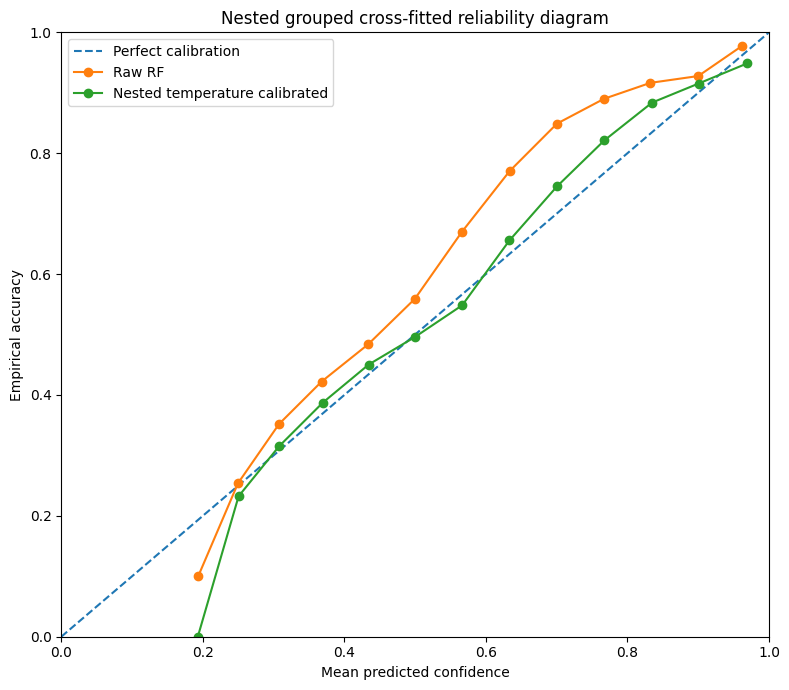

In [17]:
def plot_reliability_diagram(
    raw_reliability,
    calibrated_reliability,
    output_path,
):
    plt.figure(
        figsize=(8, 7)
    )

    plt.plot(
        [0, 1],
        [0, 1],
        linestyle="--",
        label="Perfect calibration",
    )

    raw_valid = (
        raw_reliability.dropna(
            subset=[
                "mean_confidence",
                "accuracy",
            ]
        )
    )

    calibrated_valid = (
        calibrated_reliability.dropna(
            subset=[
                "mean_confidence",
                "accuracy",
            ]
        )
    )

    plt.plot(
        raw_valid[
            "mean_confidence"
        ],
        raw_valid[
            "accuracy"
        ],
        marker="o",
        label="Raw RF",
    )

    plt.plot(
        calibrated_valid[
            "mean_confidence"
        ],
        calibrated_valid[
            "accuracy"
        ],
        marker="o",
        label="Nested temperature calibrated",
    )

    plt.xlabel(
        "Mean predicted confidence"
    )

    plt.ylabel(
        "Empirical accuracy"
    )

    plt.title(
        "Nested grouped cross-fitted reliability diagram"
    )

    plt.xlim(0, 1)
    plt.ylim(0, 1)
    plt.legend()
    plt.tight_layout()

    plt.savefig(
        output_path,
        dpi=200,
        bbox_inches="tight",
    )

    plt.show()


plot_reliability_diagram(
    pooled_raw_reliability,
    pooled_calibrated_reliability,
    PLOT_DIR
    / "01_nested_pooled_reliability_diagram.png",
)

# 15. ذخیره خروجی‌ها

In [18]:
pair_manifest_df = pd.DataFrame(
    pair_manifest_rows
)

pair_manifest_df.to_csv(
    RUN_OUTPUT_DIR
    / "00_pair_model_manifest.csv",
    index=False,
)

fold_assignment_summary.to_csv(
    RUN_OUTPUT_DIR
    / "01_fold_assignment_summary.csv",
    index=False,
)

temperatures_df.to_csv(
    RUN_OUTPUT_DIR
    / "02_nested_temperature_registry.csv",
    index=False,
)

fold_metrics_df.to_csv(
    RUN_OUTPUT_DIR
    / "03_nested_fold_metrics_long.csv",
    index=False,
)

fold_comparison.to_csv(
    RUN_OUTPUT_DIR
    / "04_nested_fold_comparison.csv",
    index=False,
)

pooled_summary.to_csv(
    RUN_OUTPUT_DIR
    / "05_nested_pooled_summary.csv",
    index=False,
)

reliability_df.to_csv(
    RUN_OUTPUT_DIR
    / "06_nested_fold_reliability_bins.csv",
    index=False,
)

pooled_raw_reliability.assign(
    probability_variant="raw"
).to_csv(
    RUN_OUTPUT_DIR
    / "07_nested_pooled_raw_reliability_bins.csv",
    index=False,
)

pooled_calibrated_reliability.assign(
    probability_variant=(
        "nested_temperature_calibrated"
    )
).to_csv(
    RUN_OUTPUT_DIR
    / "08_nested_pooled_calibrated_reliability_bins.csv",
    index=False,
)

with open(
    RUN_OUTPUT_DIR
    / "09_nested_calibration_gate.json",
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        NESTED_CALIBRATION_GATE,
        file,
        ensure_ascii=False,
        indent=2,
    )

temperature_registry = {
    str(
        int(row[
            "target_outer_fold"
        ])
    ): float(
        row[
            "temperature"
        ]
    )
    for _, row
    in temperatures_df.iterrows()
}

with open(
    RUN_OUTPUT_DIR
    / "10_nested_temperature_registry.json",
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        temperature_registry,
        file,
        ensure_ascii=False,
        indent=2,
    )

run_configuration = {
    "stage": (
        "03_nested_grouped_temperature_calibration"
    ),
    "run_mode": RUN_MODE,
    "source_outer_models": (
        "02B_legacy_RF_grouped_well_CV/full"
    ),
    "official_test_used": False,
    "outer_split_group": "WELL",
    "target_outer_folds": (
        ACTIVE_TARGET_OUTER_FOLDS
    ),
    "nested_calibration": {
        "method": (
            "pair-cached nested grouped temperature scaling"
        ),
        "outer_target_excluded_from_temperature_rows": True,
        "outer_target_excluded_from_all_inner_model_training": True,
        "inner_validation_fold_excluded_from_inner_model_training": True,
        "pair_model_count_required": int(
            len(required_pairs)
        ),
        "pair_training_folds_per_model": 3,
    },
    "legacy_random_forest": {
        "unchanged": True,
        "n_estimators": (
            RF_N_ESTIMATORS
        ),
        "max_depth": (
            RF_MAX_DEPTH
        ),
        "min_samples_split": (
            RF_MIN_SAMPLES_SPLIT
        ),
        "min_samples_leaf": (
            RF_MIN_SAMPLES_LEAF
        ),
        "random_state": (
            RANDOM_STATE_MODEL
        ),
        "feature_column_count": 26,
        "unique_feature_name_count": 25,
        "duplicate_feature_names": [
            "X_LOC"
        ],
    },
    "legacy_behavior_preserved": {
        "validation_depth_normalization_uses_validation_min_max": True,
        "train_weak_features_without_WELL": True,
        "validation_weak_features_with_WELL": True,
        "basement_added_in_dolomite_branch": True,
    },
    "temperature_bounds": [
        MIN_TEMPERATURE,
        MAX_TEMPERATURE,
    ],
    "n_calibration_bins": (
        N_BINS
    ),
    "primary_probability_for_intervention": (
        "strict nested temperature-calibrated raw RF probability"
    ),
    "legacy_refined_labels_used_for_calibration": False,
    "pair_cache_directory": str(
        PAIR_CACHE_DIR
    ),
    "save_pair_models": bool(
        SAVE_PAIR_MODELS
    ),
}

with open(
    RUN_OUTPUT_DIR
    / "11_run_configuration.json",
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        run_configuration,
        file,
        ensure_ascii=False,
        indent=2,
    )

print("All outputs saved in:")
print(RUN_OUTPUT_DIR)

print("\nNested temperature registry:")
print(
    json.dumps(
        temperature_registry,
        indent=2,
    )
)

All outputs saved in:
<historical-results-root>/03_nested_grouped_temperature_calibration/full

Nested temperature registry:
{
  "1": 0.7817853078382972,
  "2": 0.8455709005107059,
  "3": 0.7914888558618456,
  "4": 0.8141043111357217,
  "5": 0.8105943496262197
}
